# Field-aligned quads with `remesh_quads`

`remesh_quads(surface)` hands a triangle surface to an installed quad remesher, QuadriFlow (MIT) or Instant Meshes (BSD-3), run as a separate process, and returns quads aligned with a smooth cross field. Recombining a mesher's own triangles into quads (`mesh_cad_surface(quads="all")`) keeps their directions, which swirl at a sphere's poles; a field-aligned remesher places new points, so its quads stay square there. See `doc/remesh_quads.md`.

In [1]:
import os
import pathlib
import tempfile

import numpy as np
import matplotlib.pyplot as plt

import meshioplusplus as mp

try:
    import pyvista as pv
    pv.OFF_SCREEN = True
except ImportError:  # pragma: no cover
    pv = None

WORK = tempfile.mkdtemp()
CAD = pathlib.Path('..') / '..' / 'tests' / 'python' / 'meshes' / 'cad_json' / 'sphere.cad.json'
print('quad remeshers installed:', mp.remesh_quads_backends())


def scaled_jacobian(mesh):
    """Verdict's scaled Jacobian of every quad: the least corner (e1 x e2).n / |e1||e2|."""
    q = np.vstack([c.data for c in mesh.cells if c.type == 'quad'])
    p = np.asarray(mesh.points, dtype=float)[q]
    n = np.cross(p[:, 2] - p[:, 0], p[:, 3] - p[:, 1])
    n /= np.linalg.norm(n, axis=1)[:, None]
    out = np.full(len(q), np.inf)
    for k in range(4):
        e1 = p[:, (k + 1) % 4] - p[:, k]
        e2 = p[:, (k + 3) % 4] - p[:, k]
        c = np.einsum('ij,ij->i', np.cross(e1, e2), n)
        out = np.minimum(out, c / (np.linalg.norm(e1, axis=1) * np.linalg.norm(e2, axis=1)))
    return out


def quads_only(mesh):
    return mp.Mesh(mesh.points, [c for c in mesh.cells if c.type == 'quad'])


def render(panels, title, size=(1500, 600)):
    """PyVista renders coloured by each quad's scaled Jacobian, embedded through
    matplotlib; a matplotlib histogram fallback when GL is unavailable."""
    try:
        if pv is None:
            raise RuntimeError('no pyvista')
        pl = pv.Plotter(off_screen=True, shape=(1, len(panels)), window_size=size)
        for i, (mesh, sub) in enumerate(panels):
            pl.subplot(0, i)
            path = os.path.join(WORK, f'view{i}.vtu')
            m = quads_only(mesh)
            m.cell_data = {'scaled_jacobian': [scaled_jacobian(m)]}
            mp.write(path, m)
            pl.add_mesh(pv.read(path), scalars='scaled_jacobian', cmap='viridis', clim=(0, 1),
                        show_edges=True, edge_color='#1f4e79', line_width=0.3,
                        scalar_bar_args={'title': 'scaled Jacobian'})
            pl.add_text(sub, font_size=10)
            pl.camera_position = [(0.6, 0.6, 4.6), (0, 0, 0), (0, 1, 0)]
        img = pl.screenshot(return_img=True)
        pl.close()
        plt.figure(figsize=(15, 6))
        plt.imshow(img)
        plt.axis('off')
        plt.title(title)
        plt.tight_layout()
        plt.show()
    except Exception as exc:  # head-less GL fallback
        print('PyVista render skipped:', exc)
        fig, axes = plt.subplots(1, len(panels), figsize=(15, 4))
        for ax, (mesh, sub) in zip(np.atleast_1d(axes), panels):
            ax.hist(scaled_jacobian(quads_only(mesh)), bins=40, color='#2ec4b6')
            ax.set_title(sub); ax.set_xlabel('scaled Jacobian')
        fig.suptitle(title)
        plt.tight_layout()
        plt.show()

ninja: warning: premature end of file; recovering


quad remeshers installed: ['quadriflow']


## The sphere: recombination against QuadriFlow

The unit sphere meshed by `mesh_cad_surface` at `h = 0.1`. Recombined (`quads="all"`), its quads are square on the equator and poor at the poles, looking down the z axis here; QuadriFlow's are square everywhere, the cross field's eight singularities the only irregular vertices.

recombination: 2780 quads, least scaled Jacobian 0.116
quadriflow:    2645 quads, 0 triangles, least scaled Jacobian 0.250 (mean 0.987), 0.0045 from the skin


2026-11-03 10:53:01.608 (   5.751s) [    7F8C7EFDD080]vtkXOpenGLRenderWindow.:1452  WARN| bad X server connection. DISPLAY=


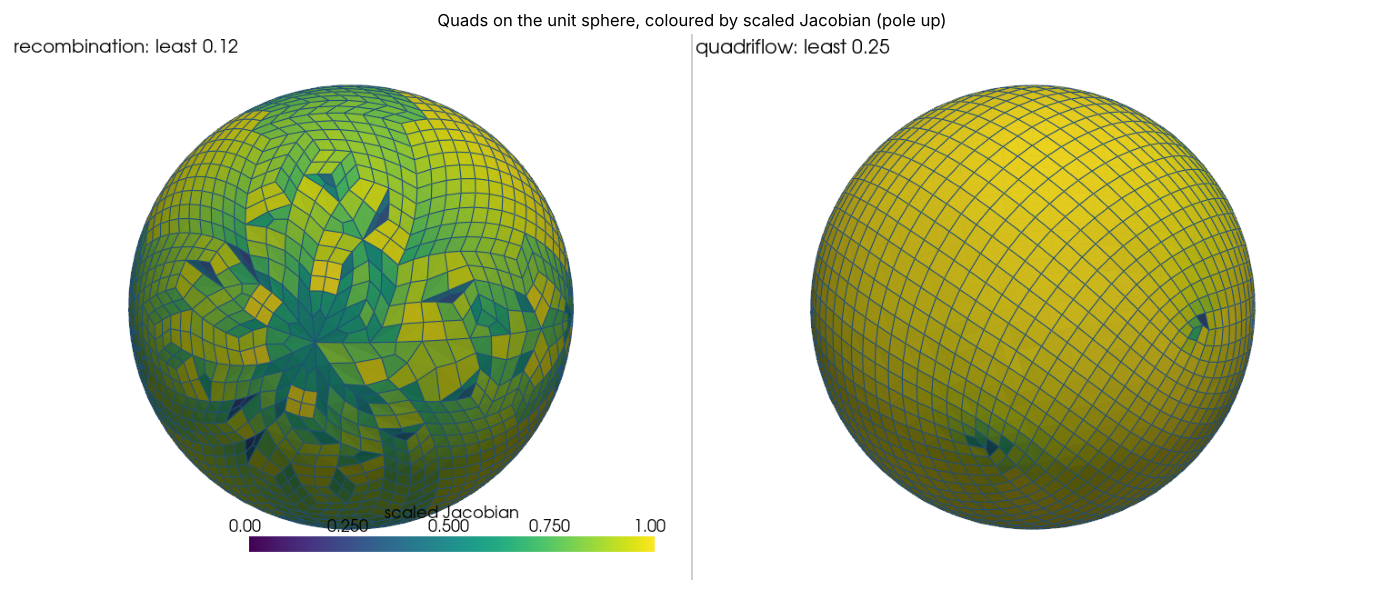

In [2]:
model = mp.read(CAD)
recombined, rr = mp.mesh_cad_surface(model, 0.1, quads='all', edges=False, return_report=True)
skin = mp.mesh_cad_surface(model, 0.1, edges=False)
quads, qr = mp.remesh_quads(skin, return_report=True)
print(f'recombination: {rr["num_quads"]} quads, least scaled Jacobian {rr["min_quad_scaled_jacobian"]:.3f}')
print(f'{qr["backend"]}:    {qr["num_quads"]} quads, {qr["num_triangles"]} triangles, least scaled '
      f'Jacobian {qr["min_scaled_jacobian"]:.3f} (mean {qr["mean_scaled_jacobian"]:.3f}), '
      f'{qr["hausdorff_to_surface"]:.4f} from the skin')
render([(recombined, f'recombination: least {rr["min_quad_scaled_jacobian"]:.2f}'),
        (quads, f'{qr["backend"]}: least {qr["min_scaled_jacobian"]:.2f}')],
       'Quads on the unit sphere, coloured by scaled Jacobian (pole up)')

The distribution says the same: recombination's quads spread down to 0.12, QuadriFlow's sit near 1 with a short tail at the singularities.

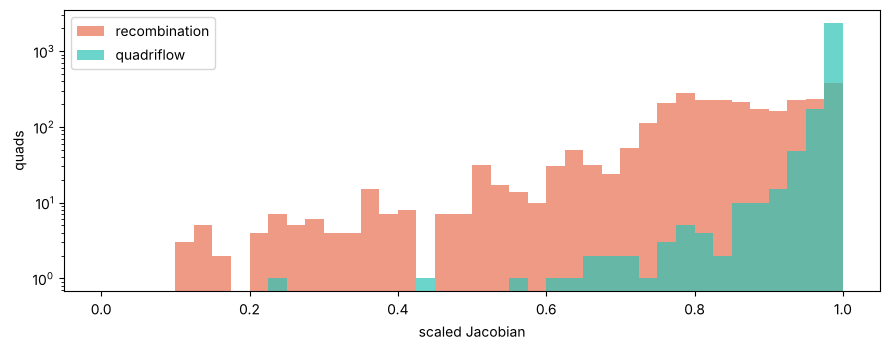

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.6))
bins = np.linspace(0, 1, 41)
ax.hist(scaled_jacobian(quads_only(recombined)), bins=bins, alpha=0.7, label='recombination', color='#e76f51')
ax.hist(scaled_jacobian(quads), bins=bins, alpha=0.7, label=qr['backend'], color='#2ec4b6')
ax.set_xlabel('scaled Jacobian'); ax.set_ylabel('quads'); ax.set_yscale('log'); ax.legend()
plt.tight_layout(); plt.show()

## The target, and the other surfaces

`target_faces` steers the count (the program treats it as a target), and the same `seed` repeats a run. The operation is the `RemeshQuads` pipeline step and the `remesh-quads` verb in both CLIs, and is on every binding; a WebAssembly build has no program to run, so there it is refused by name.

In [4]:
for target in (300, 1200, 4800):
    _, r = mp.remesh_quads(skin, target_faces=target, return_report=True)
    print(f'target {target:5d}: {r["num_quads"]:5d} quads, least scaled Jacobian {r["min_scaled_jacobian"]:.3f}')
out, rep = mp.apply_operations(skin, [{'Op': 'RemeshQuads', 'TargetFaces': 1200}])
print(rep['steps'][0])
print('meshioplusplus remesh-quads skin.stl quads.vtu --faces 1200 --json')

target   300:   320 quads, least scaled Jacobian 0.803


target  1200:  1228 quads, least scaled Jacobian 0.774


target  4800:  4070 quads, least scaled Jacobian 0.546


{'op': 'RemeshQuads', 'NumQuads': 1228.0, 'NumTriangles': 0.0, 'NumPoints': 1230.0, 'MinScaledJacobian': 0.7741975922345892, 'MeanScaledJacobian': 0.9868289551549341, 'HausdorffToSurface': 0.0052571940967692556}
meshioplusplus remesh-quads skin.stl quads.vtu --faces 1200 --json
